# Chätty, muess das dri?
_Autoren: Melanie Schiefermüller & Jimmy Wälti_ 

_Modul: 5020 KI, HS2026_

Mauer, 1.40 m hoch. Erfassen? KKVA sagt ja, Bern sagt nein, und der Geometer sagt «chunnt drufaa». 🤷

Wir fragen deshalb Gemini: Foto rein, Antwort raus. Getestet mit 4 Objektarten, mit und ohne Regeltabelle als Spickzettel.

## 1. Bilder aus den PDFs ausschneiden und speichern

### 1.1 Bibliotheken und Einstellungen

In [ ]:
# %pip install -r requirements.txt # danach Kernel neu starten

   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   ---------------------------------------- 1.2/1.2 MB 9.3 MB/s  0:00:00
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ------------------ --------------------- 4.7/10.4 MB 25.2 MB/s eta 0:00:01
   ------------------------------------- -- 9.7/10.4 MB 24.7 MB/s eta 0:00:01
   ---------------------------------------- 10.4/10.4 MB 22.1 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 25.4 MB/s  0:00:00
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   -------- ------------------------------- 6.3/29.2 MB 32.9 MB/s eta 0:00:01
   ----------------- ---------------------- 12.6/29.2 MB 31.1 MB/s eta 0:00:01
   --------------------------- ------------ 20.2/29.2 MB 33.2 MB/s eta 0:00:01
   -------------------------------------- - 28.3/29.2 MB 34.8 MB/s eta 0:00:01
   -------------------

In [1]:
import csv
from pypdf import PdfReader   # conda install -c conda-forge pypdf pillow

# Seiten zu Objektart
QUELLEN = [
    # (Datei, Kürzel, Objektart, von, bis)
    ("./data/pdfs/agi-hbav-einzelobjekte-beispiele-de-1.pdf", "be",   "Mauer",                  5,  7),
    ("./data/pdfs/agi-hbav-einzelobjekte-beispiele-de-1.pdf", "be",   "uebriger_Gebaeudeteil", 11, 17),
    ("./data/pdfs/agi-hbav-einzelobjekte-beispiele-de-1.pdf", "be",   "wichtige_Treppe",       19, 19),
    ("./data/pdfs/agi-hbav-einzelobjekte-beispiele-de-1.pdf", "be",   "Unterstand",            25, 28),
    ("./data/pdfs/kkva_detaillierungsgrad_eo.pdf",            "kkva", "Mauer",                  8, 10),
    ("./data/pdfs/kkva_detaillierungsgrad_eo.pdf",            "kkva", "uebriger_Gebaeudeteil", 15, 22),
    ("./data/pdfs/kkva_detaillierungsgrad_eo.pdf",            "kkva", "wichtige_Treppe",       23, 24),
    ("./data/pdfs/kkva_detaillierungsgrad_eo.pdf",            "kkva", "Unterstand",            33, 34),
]

MIN_GROESSE = 150   # kleinere Bilder (Logos, Icons) überspringen

### 1.2 Bilder auslesen und speichern

In [2]:
alle_zeilen = []

for pdf_datei, kuerzel, objektart, von, bis in QUELLEN:
    pdf = PdfReader(pdf_datei)

    for seite in range(von, bis + 1):               # bis + 1, damit die letzte Seite dabei ist
        alle_bilder = pdf.pages[seite - 1].images   # pypdf zählt Seiten ab 0
        nummer = 0

        for bild in alle_bilder:
            nummer = nummer + 1
            breite = bild.image.width
            hoehe = bild.image.height

            if breite >= MIN_GROESSE and hoehe >= MIN_GROESSE:
                name = kuerzel + "_" + objektart + "_s" + str(seite) + "_" + str(nummer) + "." + "png"

                datei = open("./data/bilder/" + name, "wb")
                datei.write(bild.data)
                datei.close()

                # Zeile für die Tabelle, die zwei leeren Felder füllt Jimmy aus
                alle_zeilen.append([name, kuerzel, seite, objektart, "", ""])

print(len(alle_zeilen), "Bilder gespeichert")

Invalid Lookup Table in {'/Subtype': '/Image', '/Filter': '/FlateDecode', '/BitsPerComponent': 2, '/ColorSpace': IndirectObject(371, 0, 2571322552272), '/Mask': IndirectObject(389, 0, 2571322552272), '/Width': 991, '/Height': 6, '/Type': '/XObject'}
Invalid Lookup Table in {'/Subtype': '/Image', '/Filter': '/FlateDecode', '/BitsPerComponent': 2, '/ColorSpace': IndirectObject(371, 0, 2571322552272), '/Mask': IndirectObject(389, 0, 2571322552272), '/Width': 991, '/Height': 6, '/Type': '/XObject'}
Invalid Lookup Table in {'/Subtype': '/Image', '/Filter': '/FlateDecode', '/BitsPerComponent': 2, '/ColorSpace': IndirectObject(371, 0, 2571322552272), '/Mask': IndirectObject(389, 0, 2571322552272), '/Width': 991, '/Height': 6, '/Type': '/XObject'}
Invalid Lookup Table in {'/Subtype': '/Image', '/Filter': '/FlateDecode', '/BitsPerComponent': 2, '/ColorSpace': IndirectObject(371, 0, 2571362962320), '/Mask': IndirectObject(389, 0, 2571362962320), '/Width': 991, '/Height': 6, '/Type': '/XObject'}


115 Bilder gespeichert


### 1.3 Tabelle zum Beschriften anlegen

In [3]:
#   objektart: Mauer, uebriger_Gebaeudeteil, Unterstand, wichtige_Treppe, kein_AV_Objekt
#   erfassen:  ja, nein oder abklaeren

with open("labels.csv", "w", newline="", encoding="utf-8-sig") as f: 
    schreiber = csv.writer(f, delimiter=";") 
    schreiber.writerow(["datei", "quelle", "seite", "kapitel_objektart", "objektart", "erfassen"])
    schreiber.writerows(alle_zeilen)

print("labels.csv gespeichert")

labels.csv gespeichert


## 2. Variante 1: nur Foto

Gemini bekommt nur das Bild, ohne Regeln und ohne Masse.

### 2.1 Verbindung zu Gemini

In [ ]:
from dotenv import load_dotenv # um .env-Datei zu lesen
from google import genai
from google.genai import types # für die Typen der Anfragen

load_dotenv()            # liest den Schlüssel aus .env
client = genai.Client()  # Verbindung zu Gemini herstellen

MODELL = "gemini-3.5-flash-lite"   # genau so wie in AI Studio

### 2.2 Erster Test mit einem Bild

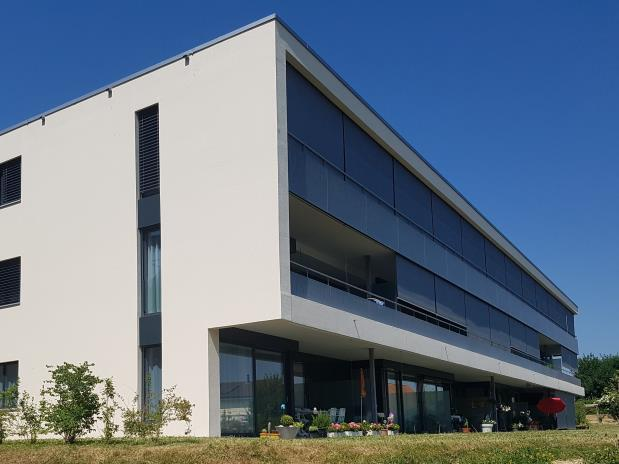

In [31]:
from IPython.display import Image

bild = open("./data/bilder/be_uebriger_Gebaeudeteil_s11_1.png", "rb").read() # rb = read binary
Image(bild, width=400)



In [32]:
# high-level-API: man muss Anfragen nicht selbst als JSON-Objekte zusammenbauen
antwort = client.models.generate_content(
    model=MODELL,
    contents=[
        types.Part.from_bytes(data=bild, mime_type="image/png"),
        "Was für ein Objekt ist auf dem Bild? Antworte auf Deutsch in einem Satz.", 
    ],
)
print(antwort.text)

Das Bild zeigt ein modernes, mehrstöckiges Wohngebäude mit hellen Putzfassaden, großflächigen Fenstern und Balkonen mit dunklen Sonnenschutzrollos.


### 2.3 Prompt und Antwortformat

Gemini muss immer im gleichen Format antworten, mit den gleichen Werten wie in labels.csv. Das Format legen wir mit einer Klasse fest (strukturierte Ausgabe).

In [49]:
import json
from typing import Literal
from pydantic import BaseModel   # BaseModel ist Basisklasse für die Validierung von Daten (kommt mit google-genai mit)

PROMPT_V1 = """Du bist Fachperson für die amtliche Vermessung im Kanton Bern.
Schau dir das Foto an und beantworte zwei Fragen:
1. Welche Einzelobjektart ist zu sehen? Wenn keine passt, wähle kein_AV_Objekt.
   Wenn mehrere Objekte zu sehen sind, nimm das wichtigste.
2. Wird das Objekt nach der Praxis im Kanton Bern in der amtlichen Vermessung erfasst?
   Wenn das aus dem Foto allein nicht sicher zu entscheiden ist, wähle abklaeren.
Begründe kurz auf Deutsch."""

# So muss Gemini antworten, nur diese Werte sind erlaubt
class Antwort(BaseModel):
    objektart: Literal["Mauer", "uebriger_Gebaeudeteil", "Unterstand", "wichtige_Treppe", "kein_AV_Objekt"]
    erfassen: Literal["ja", "nein", "abklaeren"]
    begruendung: str

### 2.4 Test mit einem Bild

In [50]:
bild = open("./data/bilder/be_uebriger_Gebaeudeteil_s11_1.png", "rb").read()

antwort = client.models.generate_content(
    model=MODELL,
    contents=[
        types.Part.from_bytes(data=bild, mime_type="image/png"),
        PROMPT_V1,
    ],
    config=types.GenerateContentConfig(
        response_mime_type="application/json",
        response_schema=Antwort,   # Gemini muss dieses Format einhalten
    ),
)

ergebnis = json.loads(antwort.text)   # JSON-Text in ein Dictionary umwandeln
print("Objektart:  ", ergebnis["objektart"])
print("Erfassen:   ", ergebnis["erfassen"])
print("Begründung: ", ergebnis["begruendung"])

Objektart:   uebriger_Gebaeudeteil
Erfassen:    nein
Begründung:  Es ist ein vorspringender Gebäudeteil (Balkone und Vordach), der statisch mit dem Hauptgebäude verbunden ist und daher als Teil des Hauptgebäudes gilt und nicht als separates Einzelobjekt erfasst wird.


### 2.5 Alle Bilder an Gemini schicken

Zwischen zwei Anfragen warten wir 5 Sekunden, damit wir unter dem Gratis-Limit von 15 Anfragen pro Minute bleiben.

In [51]:
import time

# Bildnamen aus labels.csv lesen
with open("labels.csv", newline="", encoding="utf-8-sig") as f:
    alle_labels = list(csv.DictReader(f, delimiter=";"))   # DictReader liefert ein Dictionary pro Zeile

alle_antworten = []

for eintrag in alle_labels:
    name = eintrag["datei"]
    bild = open("./data/bilder/" + name, "rb").read()

    antwort = client.models.generate_content(
        model=MODELL,
        contents=[
            types.Part.from_bytes(data=bild, mime_type="image/png"),
            PROMPT_V1,
        ],
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=Antwort,
            temperature=0,
        ),
    )
    ergebnis = json.loads(antwort.text)

    alle_antworten.append([name, ergebnis["objektart"], ergebnis["erfassen"], ergebnis["begruendung"]])
    print(name, ":", ergebnis["objektart"], ",", ergebnis["erfassen"])

    time.sleep(5)   # unter dem Limit bleiben

print(len(alle_antworten), "Antworten erhalten")

be_Mauer_s6_1.png : Unterstand , ja
be_Mauer_s6_2.png : Mauer , ja
be_Mauer_s6_3.png : Mauer , ja
be_Mauer_s6_4.png : kein_AV_Objekt , nein
be_Mauer_s6_5.png : kein_AV_Objekt , nein
be_Mauer_s7_1.png : Mauer , nein
be_Mauer_s7_2.png : Mauer , nein
be_Mauer_s7_3.png : Mauer , nein
be_Mauer_s7_4.png : Mauer , ja
be_uebriger_Gebaeudeteil_s11_1.png : uebriger_Gebaeudeteil , ja
be_uebriger_Gebaeudeteil_s11_2.png : uebriger_Gebaeudeteil , ja
be_uebriger_Gebaeudeteil_s12_1.png : uebriger_Gebaeudeteil , nein
be_uebriger_Gebaeudeteil_s12_2.png : uebriger_Gebaeudeteil , nein
be_uebriger_Gebaeudeteil_s12_3.png : uebriger_Gebaeudeteil , ja
be_uebriger_Gebaeudeteil_s12_4.png : uebriger_Gebaeudeteil , nein
be_uebriger_Gebaeudeteil_s13_1.png : Unterstand , ja
be_uebriger_Gebaeudeteil_s13_2.png : uebriger_Gebaeudeteil , ja
be_uebriger_Gebaeudeteil_s13_3.png : Unterstand , ja
be_uebriger_Gebaeudeteil_s13_4.png : uebriger_Gebaeudeteil , ja
be_uebriger_Gebaeudeteil_s14_1.png : uebriger_Gebaeudeteil , ja


ConnectError: [SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1081)

### 2.6 Antworten speichern

In [ ]:
with open("antworten_v1.csv", "w", newline="", encoding="utf-8-sig") as f:
    schreiber = csv.writer(f, delimiter=";")
    schreiber.writerow(["datei", "objektart", "erfassen", "begruendung"])
    schreiber.writerows(alle_antworten)

print("antworten_v1.csv gespeichert")

Objektart:   uebriger_Gebaeudeteil
Erfassen:    ja
Begründung:  Es handelt sich um vorspringende Gebäudeteile wie Balkone und Loggias, die gemäss den kantonalen Richtlinien zur Erfassung von Gebäudeteilen in der amtlichen Vermessung als 'übriger Gebäudeteil' erfasst werden.
